<a href="https://colab.research.google.com/github/Raffi38321/ProyekAkhir_5C_Students-Dropout-Academic-Success/blob/main/03_varian_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tahap 3: Pemodelan Varian 3 — Algoritma Pembanding Naive Bayes (`03_varian_3.ipynb`)
**Nama Anggota:** [Isi Nama Anggota 3]  
**NIM:** [Isi NIM]  
**Kelas / Paket:** Informatika 5C — Paket 5C-5 (*Students Dropout & Academic Success*)  
**Metode & Varian:** Klasifikasi *k*-NN dibandingkan *Naive Bayes* — **Varian 3 (Algoritma Pembanding: Gaussian Naive Bayes)**  

### Konfigurasi Varian 3:
* **Algoritma:** `GaussianNB` sebagai algoritma pembanding terhadap *k*-NN (Varian 1 dan Varian 2). Parameter `var_smoothing` disetel menggunakan *5-Fold Stratified Cross-Validation* pada data latih, dan hasilnya dibandingkan dengan konfigurasi bawaan (`var_smoothing = 1e-9`).
* **Data Masukan:** Data hasil praproses dari `02_praproses.ipynb` (`train_processed.csv` dan `test_processed.csv`) yang terdiri atas 236 fitur hasil *One-Hot Encoding* dan *StandardScaler* (bebas kebocoran data). Data yang sama persis dengan Varian 1 dan 2 agar perbandingan adil.
* **Tujuan:** Membandingkan pendekatan probabilistik (Naive Bayes) dengan pendekatan berbasis jarak (*k*-NN) pada data yang sama, serta menguji dampak asumsi independensi antarfitur dan sifat fitur *one-hot* terhadap performa Naive Bayes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# Muat data hasil Tahap 2 (02_praproses.ipynb)
train_df = pd.read_csv('train_processed.csv')
test_df = pd.read_csv('test_processed.csv')

X_train = train_df.drop(columns=['Target'])
y_train = train_df['Target']

X_test = test_df.drop(columns=['Target'])
y_test = test_df['Target']

print("Ukuran X_train:", X_train.shape, "| y_train:", y_train.shape)
print("Ukuran X_test :", X_test.shape, "| y_test :", y_test.shape)

Ukuran X_train: (3539, 236) | y_train: (3539,)
Ukuran X_test : (885, 236) | y_test : (885,)


In [2]:
# Pemeriksaan asumsi Naive Bayes: independensi antarfitur numerik
# (pasangan dengan |korelasi| > 0,8 melanggar asumsi independensi)
num_cols = [c for c in X_train.columns if c.startswith('num__')]
kor = X_train[num_cols].corr().abs()
pasangan = kor.where(np.triu(np.ones(kor.shape), k=1).astype(bool)).stack()
pasangan = pasangan[pasangan > 0.8].sort_values(ascending=False)
print(f"Jumlah pasangan fitur numerik berkorelasi > 0,8: {len(pasangan)}")
display(pasangan.round(4).to_frame('|Korelasi|'))

# Pemeriksaan sifat fitur: proporsi fitur biner (hasil One-Hot Encoding)
n_biner = sum(X_train[c].nunique() <= 2 for c in X_train.columns)
print(f"\nFitur biner (0/1, hasil One-Hot) : {n_biner} dari {X_train.shape[1]} fitur")

Jumlah pasangan fitur numerik berkorelasi > 0,8: 4


,,|Korelasi|
num__Curricular units 1st sem (credited),num__Curricular units 2nd sem (credited),0.9475
num__Curricular units 1st sem (enrolled),num__Curricular units 2nd sem (enrolled),0.9435
num__Curricular units 1st sem (approved),num__Curricular units 2nd sem (approved),0.9065
num__Curricular units 1st sem (grade),num__Curricular units 2nd sem (grade),0.8391



Fitur biner (0/1, hasil One-Hot) : 217 dari 236 fitur


GaussianNB bawaan -> Akurasi: 0.2441 | F1 Macro: 0.2171


,var_smoothing,CV_Accuracy_Mean,CV_Accuracy_Std,CV_F1_Macro_Mean,CV_F1_Macro_Std
0,0.0000,0.2368,0.0102,0.2115,0.0115
1,0.0000,0.2410,0.0098,0.2178,0.0110
2,0.0000,0.2481,0.0123,0.2271,0.0131
3,0.0000,0.2563,0.0156,0.2382,0.0160
4,0.0000,0.2744,0.0198,0.2619,0.0210
5,0.0001,0.3620,0.0906,0.3616,0.0861
6,0.0010,0.5906,0.0215,0.5510,0.0177
7,0.0100,0.6468,0.0198,0.5975,0.0196
8,0.0500,0.6830,0.0204,0.6166,0.0236
9,0.1000,0.6945,0.0169,0.6206,0.0186



Nilai var_smoothing optimal berdasarkan 5-Fold CV : 0.2
Rata-rata CV F1-Score (Macro)                    : 0.6219
Rata-rata CV Akurasi                             : 0.7008


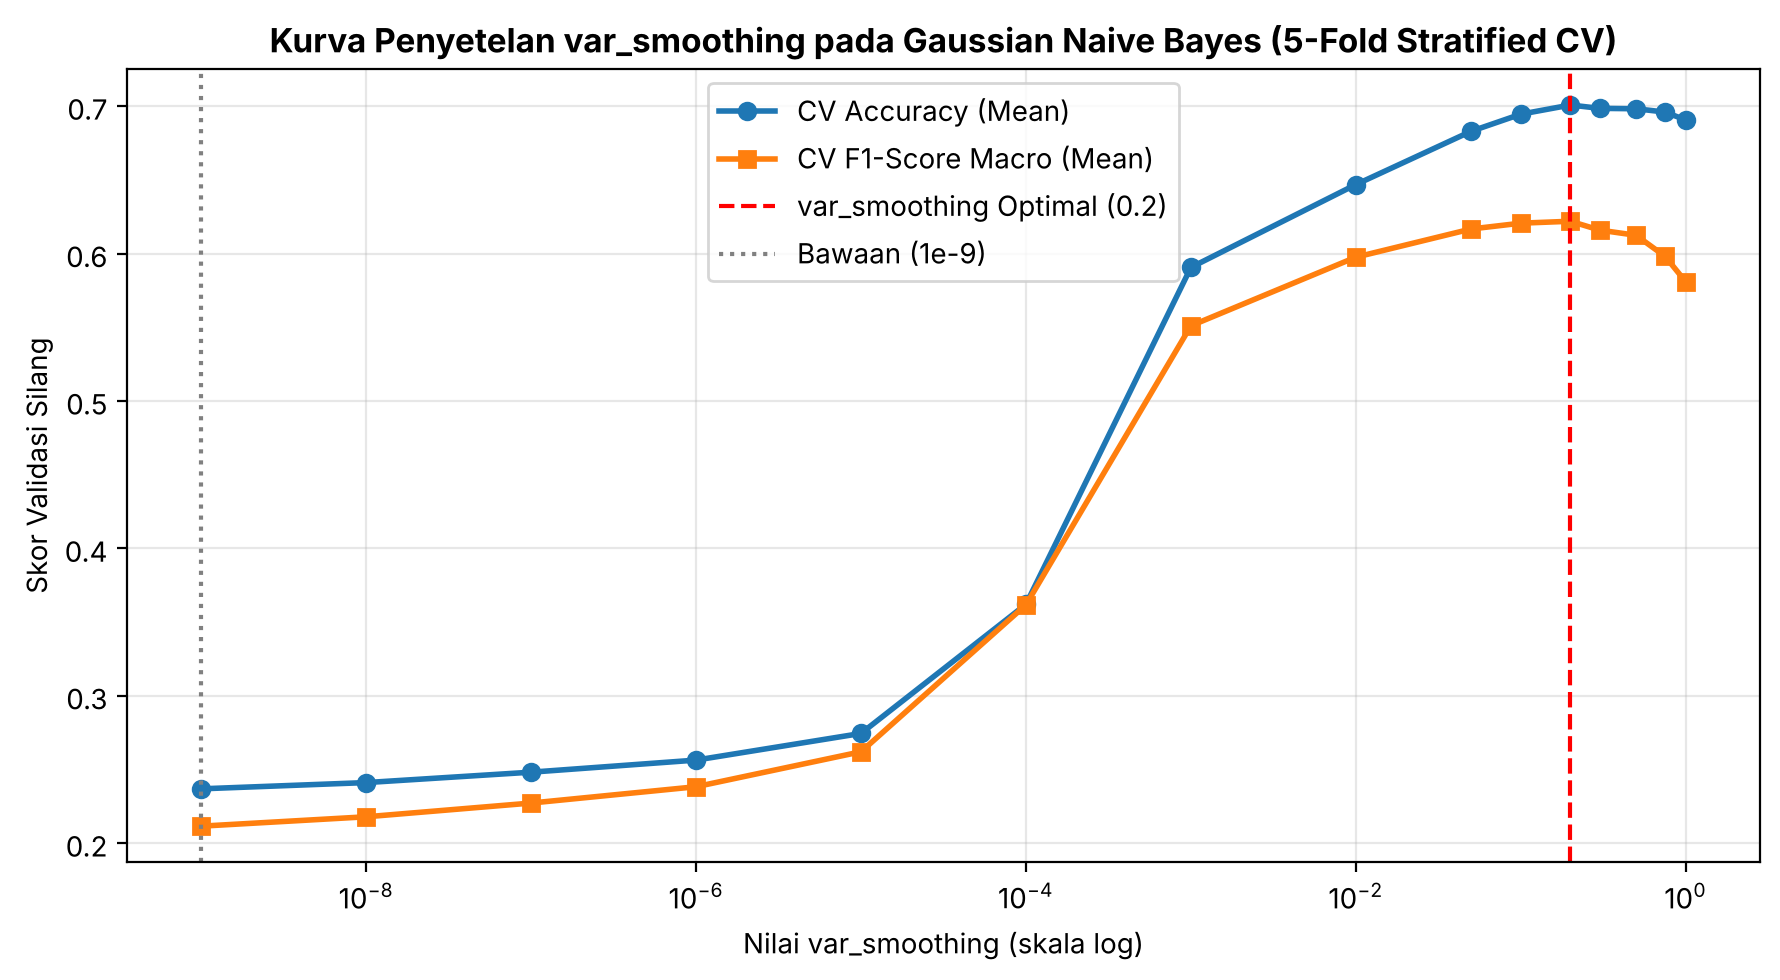

In [3]:
# Baseline: GaussianNB dengan parameter bawaan (var_smoothing = 1e-9)
nb_default = GaussianNB()
nb_default.fit(X_train, y_train)
y_pred_default = nb_default.predict(X_test)

acc_default = accuracy_score(y_test, y_pred_default)
f1_default = f1_score(y_test, y_pred_default, average='macro')
print(f"GaussianNB bawaan -> Akurasi: {acc_default:.4f} | F1 Macro: {f1_default:.4f}")

# Kandidat nilai var_smoothing (skala logaritmik, dari sangat kecil hingga besar)
vs_candidates = [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2,
                 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tuning_results = []

for vs in vs_candidates:
    nb = GaussianNB(var_smoothing=vs)

    cv_acc = cross_val_score(nb, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    cv_f1 = cross_val_score(nb, X_train, y_train, cv=cv, scoring='f1_macro', n_jobs=-1)

    tuning_results.append({
        'var_smoothing': vs,
        'CV_Accuracy_Mean': cv_acc.mean(),
        'CV_Accuracy_Std': cv_acc.std(),
        'CV_F1_Macro_Mean': cv_f1.mean(),
        'CV_F1_Macro_Std': cv_f1.std()
    })

df_tuning = pd.DataFrame(tuning_results)
display(df_tuning.round(4))

# Tentukan var_smoothing terbaik berdasarkan rata-rata F1-Score Macro tertinggi pada validasi silang
best_idx = df_tuning['CV_F1_Macro_Mean'].idxmax()
best_vs = float(df_tuning.loc[best_idx, 'var_smoothing'])
best_cv_f1 = df_tuning.loc[best_idx, 'CV_F1_Macro_Mean']
best_cv_acc = df_tuning.loc[best_idx, 'CV_Accuracy_Mean']

print(f"\nNilai var_smoothing optimal berdasarkan 5-Fold CV : {best_vs}")
print(f"Rata-rata CV F1-Score (Macro)                    : {best_cv_f1:.4f}")
print(f"Rata-rata CV Akurasi                             : {best_cv_acc:.4f}")

# Visualisasi kurva penyetelan parameter var_smoothing
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df_tuning['var_smoothing'], df_tuning['CV_Accuracy_Mean'], marker='o', label='CV Accuracy (Mean)', linewidth=2)
ax.plot(df_tuning['var_smoothing'], df_tuning['CV_F1_Macro_Mean'], marker='s', label='CV F1-Score Macro (Mean)', linewidth=2)
ax.axvline(best_vs, color='red', linestyle='--', label=f'var_smoothing Optimal ({best_vs})')
ax.axvline(1e-9, color='gray', linestyle=':', label='Bawaan (1e-9)')
ax.set_xscale('log')

ax.set_title('Kurva Penyetelan var_smoothing pada Gaussian Naive Bayes (5-Fold Stratified CV)', fontsize=12, fontweight='bold')
ax.set_xlabel('Nilai var_smoothing (skala log)')
ax.set_ylabel('Skor Validasi Silang')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
# Latih model final Varian 3 dengan var_smoothing terbaik pada seluruh data latih
model_v3 = GaussianNB(var_smoothing=best_vs)
model_v3.fit(X_train, y_train)

# Prediksi pada data uji
y_pred = model_v3.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro')
rec_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')
baseline = (y_test == 'Graduate').mean()

print(f"=== HASIL EVALUASI VARIAN 3: GAUSSIAN NAIVE BAYES (var_smoothing = {best_vs}) ===")
print(f"Baseline Kelas Mayoritas : {baseline:.4f} ({baseline*100:.2f}%)")
print(f"Akurasi Model            : {acc:.4f} ({acc*100:.2f}%)")
print(f"Peningkatan vs Baseline  : +{(acc - baseline)*100:.2f}%")
print(f"Precision (Macro)        : {prec_macro:.4f}")
print(f"Recall (Macro)           : {rec_macro:.4f}")
print(f"F1-Score (Macro)         : {f1_macro:.4f}")
print(f"F1-Score (Weighted)      : {f1_weighted:.4f}")

print("\n=== LAPORAN KLASIFIKASI PER KELAS ===")
print(classification_report(y_test, y_pred, digits=4))

=== HASIL EVALUASI VARIAN 3: GAUSSIAN NAIVE BAYES (var_smoothing = 0.2) ===
Baseline Kelas Mayoritas : 0.4994 (49.94%)
Akurasi Model            : 0.6949 (69.49%)
Peningkatan vs Baseline  : +19.55%
Precision (Macro)        : 0.6328
Recall (Macro)           : 0.6086
F1-Score (Macro)         : 0.6160
F1-Score (Weighted)      : 0.6870

=== LAPORAN KLASIFIKASI PER KELAS ===
              precision    recall  f1-score   support

     Dropout     0.7913    0.6408    0.7082       284
    Enrolled     0.3669    0.3208    0.3423       159
    Graduate     0.7403    0.8643    0.7975       442

    accuracy                         0.6949       885
   macro avg     0.6328    0.6086    0.6160       885
weighted avg     0.6896    0.6949    0.6870       885



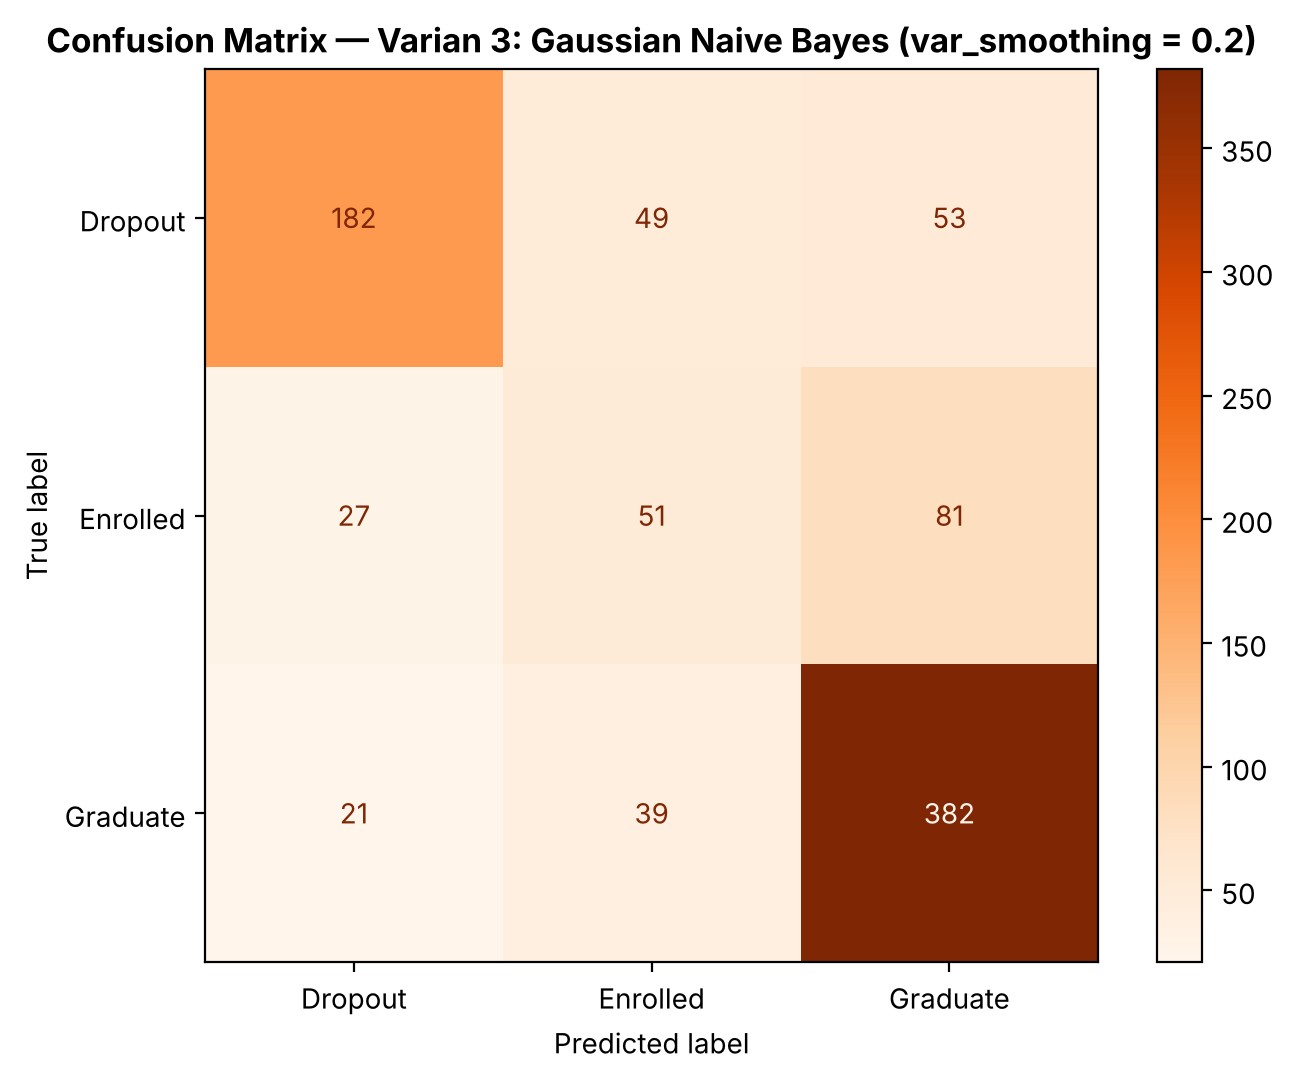

In [5]:
labels = ['Dropout', 'Enrolled', 'Graduate']
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(7, 5.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Oranges', ax=ax, values_format='d')
plt.title(f'Confusion Matrix — Varian 3: Gaussian Naive Bayes (var_smoothing = {best_vs})', fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

In [6]:
# Rekap hasil Varian 3 dan perbandingan dengan Varian 1 (k-NN k=5) dan Varian 2 (k-NN k=11)
perbandingan_semua = pd.DataFrame([
    {
        'Varian': 'Varian 1 (Dasar)',
        'Model': 'k-NN (k=5)',
        'Akurasi': 0.7028,
        'Precision_Macro': 0.6320,
        'Recall_Macro': 0.6131,
        'F1_Macro': 0.6182,
        'F1_Weighted': 0.6909
    },
    {
        'Varian': 'Varian 2 (Parameter k)',
        'Model': 'k-NN (k=11)',
        'Akurasi': 0.7164,
        'Precision_Macro': 0.6568,
        'Recall_Macro': 0.6099,
        'F1_Macro': 0.6184,
        'F1_Weighted': 0.6950
    },
    {
        'Varian': 'Varian 3 (Pembanding, bawaan)',
        'Model': 'GaussianNB (var_smoothing=1e-9)',
        'Akurasi': round(acc_default, 4),
        'Precision_Macro': round(precision_score(y_test, y_pred_default, average='macro'), 4),
        'Recall_Macro': round(recall_score(y_test, y_pred_default, average='macro'), 4),
        'F1_Macro': round(f1_default, 4),
        'F1_Weighted': round(f1_score(y_test, y_pred_default, average='weighted'), 4)
    },
    {
        'Varian': 'Varian 3 (Pembanding, tuning)',
        'Model': f'GaussianNB (var_smoothing={best_vs})',
        'Akurasi': round(acc, 4),
        'Precision_Macro': round(prec_macro, 4),
        'Recall_Macro': round(rec_macro, 4),
        'F1_Macro': round(f1_macro, 4),
        'F1_Weighted': round(f1_weighted, 4)
    }
])

display(perbandingan_semua)

# Simpan model terbaik Varian 3
joblib.dump(model_v3, 'model_varian_3.pkl')

,Varian,Model,Akurasi,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted
0,Varian 1 (Dasar),k-NN (k=5),0.7028,0.6320,0.6131,0.6182,0.6909
1,Varian 2 (Parameter k),k-NN (k=11),0.7164,0.6568,0.6099,0.6184,0.6950
2,"Varian 3 (Pembanding, bawaan)",GaussianNB (var_smoothing=1e-9),0.2441,0.4798,0.3922,0.2171,0.1675
3,"Varian 3 (Pembanding, tuning)",GaussianNB (var_smoothing=0.2),0.6949,0.6328,0.6086,0.6160,0.6870


['model_varian_3.pkl']

### Analisis & Penafsiran Hasil Varian 3 (Algoritma Pembanding: Gaussian Naive Bayes)
1. **Pengaruh Parameter `var_smoothing` pada Validasi Silang:**
   * *GaussianNB* dengan parameter bawaan (`var_smoothing = 1e-9`) hanya mencapai akurasi **24,41%** dan *F1-Score Macro* **0,2171** pada data uji, jauh di bawah *baseline* kelas mayoritas (**49,94%**). Penyebabnya, **217 dari 236 fitur** bernilai biner hasil *One-Hot Encoding* yang pada kelas tertentu hampir selalu 0, sehingga varians per kelas mendekati nol dan likelihood Gaussian menjadi sangat ekstrem; satu fitur langka saja dapat mendominasi probabilitas posterior.
   * Peningkatan `var_smoothing` menstabilkan estimasi varians. Skor validasi silang naik tajam dari **0,2115** (*F1 Macro*, 1e-9) hingga puncak pada **`var_smoothing` = 0,2** dengan *F1-Score Macro* **0,6219** dan akurasi validasi silang **70,08%**, lalu kembali menurun pada nilai lebih besar (*F1 Macro* 0,5808 pada 1,0) karena varians terlalu dibesarkan sehingga model kehilangan daya pembeda.

2. **Perbandingan terhadap Varian 1 ($k = 5$) dan Varian 2 ($k = 11$):**
   * Pada data uji, Varian 3 (tuning) memperoleh akurasi **69,49%** (naik **+19,55%** di atas *baseline* 49,94%), *Precision Macro* **0,6328**, *Recall Macro* **0,6086**, *F1-Score Macro* **0,6160**, dan *F1-Score Weighted* **0,6870**.
   * Dibandingkan *k*-NN, *Naive Bayes* hasil penyetelan berada sedikit di bawah Varian 1 (akurasi 70,28%; *F1 Macro* 0,6182) dan Varian 2 (akurasi 71,64%; *F1 Macro* 0,6184). Selisih *F1 Macro* hanya sekitar 0,002, sehingga kedua pendekatan praktis setara pada data ini, sedangkan dari sisi akurasi *k*-NN (k = 11) unggul sekitar 2,15 poin persentase.
   * Penskalaan tidak diperlukan oleh *Naive Bayes* (data sudah terskala dari Tahap 2 sehingga tidak berpengaruh pada urutan probabilitas), sedangkan pada *k*-NN penskalaan wajib karena jarak Euclidean sensitif terhadap skala fitur.

3. **Pelanggaran Asumsi Independensi:**
   * Ditemukan **4 pasangan fitur numerik berkorelasi > 0,8**, seluruhnya antara semester 1 dan semester 2 (misalnya *credited* 0,9475, *enrolled* 0,9435, *approved* 0,9065, *grade* 0,8391). Asumsi independensi bersyarat *Naive Bayes* dilanggar karena informasi yang sama dihitung dua kali, sehingga probabilitas posterior cenderung terlalu ekstrem. Hal ini menjadi salah satu penjelasan mengapa *Naive Bayes* tidak melampaui *k*-NN.

4. **Evaluasi per Kelas (*Confusion Matrix*):**
   * Kelas `Graduate` tetap dikenali paling baik (*recall* **86,43%**, 382 dari 442 sampel tepat) dan `Dropout` memiliki *precision* **79,13%** (*recall* 64,08%).
   * Kelas `Enrolled` tetap tersulit (*precision* **36,69%**, *F1* **0,3423**), namun *recall*-nya (**32,08%**, 51 dari 159 sampel) lebih tinggi daripada Varian 2 (25,79%). Artinya *Naive Bayes* sedikit lebih sensitif terhadap kelas minoritas, dengan harga *recall* `Graduate` dan `Dropout` yang lebih rendah dibanding *k*-NN. Sebanyak 81 sampel `Enrolled` masih salah diprediksi sebagai `Graduate`, konsisten dengan tumpang tindih karakteristik akademik semester 1–2 kedua kelas tersebut.

5. **Kesimpulan Varian 3:** *Naive Bayes* bukan pilihan unggul untuk paket ini; performanya kompetitif hanya setelah `var_smoothing` disetel, dan tanpa penyetelan modelnya gagal total. Temuan ini menegaskan bahwa fitur *one-hot* berdimensi tinggi serta korelasi antarfitur membuat asumsi *Naive Bayes* kurang cocok, sedangkan *k*-NN yang berbasis jarak pada data terskala lebih stabil.